# Lab 24.3: A Colorado-Style Disparity Test and Its Explanation

This notebook runs the two steps of the Colorado Division of Insurance's **draft** quantitative testing regulation for life insurance underwriting (exposed September 2023, not adopted as of November 2026) on synthetic data. It reproduces Figure 24.6 (`ch24-disparity`). Groups are invented labels; the group differences are built into the simulation and say nothing about real people.

You may edit only the two settings in the next cell. Run everything once with the defaults first.

In [1]:
DECLINE_SHARE = 0.15                     # share of applicants the insurer declines
INDEX_SHIFT = [0.0, -0.8, -1.0, -0.2]    # mean shift of the external index by group (reference, 1, 2, 3)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def fit_logit(X, y, l2=1e-6, iters=50):
    """Newton-Raphson logistic regression with intercept; returns coefficients and standard errors."""
    Z = np.column_stack([np.ones(len(X)), X])
    b = np.zeros(Z.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-Z @ b))
        H = Z.T @ (Z * (p * (1 - p))[:, None]) + l2 * np.eye(Z.shape[1])
        step = np.linalg.solve(H, Z.T @ (y - p) - l2 * b)
        b += step
        if np.abs(step).max() < 1e-10:
            break
    p = 1 / (1 + np.exp(-Z @ b))
    H = Z.T @ (Z * (p * (1 - p))[:, None])
    return b, np.sqrt(np.diag(np.linalg.inv(H)))


## 1. Synthetic underwriting data

Traditional factors (medical score, family history, prescriptions) depend on true health. The external lifestyle index (think purchasing or property data) depends a little on health and, by construction, on group. The controls allowed by the draft are age, sex, tobacco use, face amount and policy type.

In [3]:
def life_data(n=40000, seed=169, shift=INDEX_SHIFT):
    rng = np.random.default_rng(seed)
    g = rng.choice(4, n, p=[0.6, 0.18, 0.12, 0.10])
    age = rng.uniform(25, 65, n); male = rng.random(n) < 0.5; tobacco = rng.random(n) < 0.15
    face = np.exp(rng.normal(12.3, 0.6, n)); perm = rng.random(n) < 0.3
    health = rng.normal(0, 1, n)
    medical = health + 0.03 * (age - 45) + 0.6 * tobacco + rng.normal(0, 0.6, n)
    family = (rng.random(n) < 0.15 + 0.1 * (health > 1)).astype(float)
    rx = rng.poisson(np.exp(0.2 * health + 0.01 * (age - 45)), n).astype(float)
    lifestyle = 0.45 * (-health) + np.array(shift)[g] + rng.normal(0, 1, n)
    risk = -3.4 + 0.06 * (age - 45) + 0.7 * tobacco + 0.25 * male + 0.9 * health + 0.3 * family
    claim = (rng.random(n) < 1 / (1 + np.exp(-risk))).astype(float)
    controls = np.column_stack([age, male, tobacco, np.log(face), perm]).astype(float)
    return dict(g=g, controls=controls, trad=np.column_stack([medical, family, rx]),
                ecdis=lifestyle[:, None], claim=claim)

D = life_data()
print("applicants:", len(D["g"]), " claim rate:", D["claim"].mean().round(3))

applicants: 40000  claim rate: 0.07


## 2. The insurer's underwriting model

A logistic model of claims on age, sex, tobacco, the traditional factors and the external index; the riskiest `DECLINE_SHARE` are declined.

In [4]:
UNDERWRITING = ["Age", "Sex", "Tobacco", "Medical score", "Family history", "Prescriptions",
                "External lifestyle index"]

def underwrite(D, drop=None, share=DECLINE_SHARE):
    U = np.column_stack([D["trad"], -D["ecdis"]])
    keep = [j for j in range(U.shape[1]) if j != drop]
    F = np.column_stack([D["controls"][:, [0, 1, 2]], U[:, keep]])
    Fz = (F - F.mean(0)) / F.std(0)
    b, _ = fit_logit(Fz, D["claim"])
    s = b[0] + Fz @ b[1:]
    return (s > np.quantile(s, 1 - share)).astype(float), b[1:], Fz

dec, w, Fz = underwrite(D)
pd.Series({f"group {k}": dec[D["g"] == k].mean() for k in range(4)}, name="decline rate").round(3)

group 0    0.146
group 1    0.154
group 2    0.164
group 3    0.147
Name: decline rate, dtype: float64

*Checkpoint 1 (defaults):* decline rates 0.146 (reference), 0.154, 0.164, 0.147.

## 3. Step 1: is there a statistically significant difference?

As in the draft: logistic regression of the decision on group indicators (reference group omitted) plus the allowed controls.

In [5]:
from math import erf, sqrt

def step1(D, decline):
    G = np.column_stack([(D["g"] == k) for k in (1, 2, 3)]).astype(float)
    C = D["controls"]
    b, se = fit_logit(np.column_stack([G, (C - C.mean(0)) / C.std(0)]), decline)
    p = [2 * (1 - 0.5 * (1 + erf(abs(bb / ss) / sqrt(2)))) for bb, ss in zip(b[1:4], se[1:4])]
    return pd.DataFrame({"log_odds": b[1:4], "se": se[1:4], "p_value": p},
                        index=["group 1", "group 2", "group 3"]).round(4)

t1 = step1(D, dec)
t1

,log_odds,se,p_value
group 1,0.1002,0.0423,0.0179
group 2,0.2017,0.0487,0.0000
group 3,0.0221,0.0546,0.6855


*Checkpoint 2 (defaults):* group 2 log-odds about 0.202 with p below 0.001; group 1 about 0.100 (p about 0.018); group 3 not significant.

## 4. Step 2: which variables carry the difference?

The draft says only that each variable in the model is tested to find which contribute. Here is **one** way to do it: split the gap in average model score between each group and the reference group into one additive term per variable (weight times difference in group means). The terms add up exactly to the gap. Chapter 8 explains why other definitions can give other answers when inputs are correlated.

In [6]:
ref = Fz[D["g"] == 0].mean(0)
contrib = pd.DataFrame({f"group {k}": w * (Fz[D["g"] == k].mean(0) - ref) for k in (1, 2, 3)},
                       index=UNDERWRITING)
contrib.loc["total gap"] = contrib.sum()
contrib.round(4)

,group 1,group 2,group 3
Age,-0.0049,0.0004,0.0048
Sex,-0.0016,-0.0024,-0.0030
Tobacco,0.0001,-0.0011,-0.0016
Medical score,-0.0004,-0.0016,-0.0122
Family history,0.0031,0.0037,0.0037
Prescriptions,0.0008,0.0014,-0.0013
External lifestyle index,0.0637,0.0815,0.0162
total gap,0.0609,0.0819,0.0065


*Checkpoint 3 (defaults):* for group 2 the external lifestyle index contributes about +0.082 of a total gap of about +0.082; every other variable contributes almost nothing.

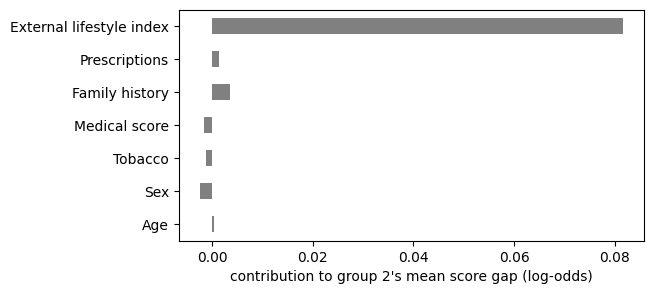

In [7]:
ax = contrib.drop("total gap")["group 2"].plot.barh(figsize=(6, 3), color="gray")
ax.set_xlabel("contribution to group 2's mean score gap (log-odds)"); plt.show()

## 5. Remediation: refit without the external index, and test again

In [8]:
dec_r, _, _ = underwrite(D, drop=3)
display(step1(D, dec_r))
pd.Series({f"group {k}": dec_r[D["g"] == k].mean() for k in range(4)}, name="decline rate").round(3)

,log_odds,se,p_value
group 1,-0.0291,0.0428,0.4971
group 2,0.0289,0.0497,0.5601
group 3,-0.0024,0.0543,0.9642


group 0    0.151
group 1    0.146
group 2    0.151
group 3    0.149
Name: decline rate, dtype: float64

*Checkpoint 4 (defaults):* group 2 log-odds about 0.029, p about 0.56; decline rates 0.149, 0.146, 0.151, 0.149.

How much predictive power did remediation cost? Compare how well each set of decisions separates claims from non-claims.

In [9]:
def claim_capture(decline):
    return decline[D["claim"] == 1].mean()      # share of eventual claims that were declined
print("claims declined, with index:   ", round(claim_capture(dec), 3))
print("claims declined, without index:", round(claim_capture(dec_r), 3))

claims declined, with index:    0.472
claims declined, without index: 0.468


## 6. Experiments and hand-in

1. Set `INDEX_SHIFT = [0, 0, 0, 0]` and rerun. What happens in steps 1 and 2? Why?
2. Restore the default shift and set `DECLINE_SHARE = 0.05`, then `0.30`. How does the significance in step 1 change, and why might a regulator fix the decline share or test at several?

Hand in the step 1 table, the step 2 attribution, the remediation result and half a page on what this test cannot tell you: think about estimated (not observed) group membership, the choice of attribution method, and variables that are correlated with the one you removed.